# 01 · Exploratory data analysis

IBM Telco Customer Churn: one row per customer with demographics, contracted services, billing and whether they left.

What I want out of this notebook:

1. Confirm the data is usable (completeness, uniqueness, types).
2. Measure how much each variable separates churners from non-churners (WoE/IV and univariate Gini).
3. Find redundancies and interactions that matter for feature engineering.
4. Check that the frozen train / test / holdout / production split is representative.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from churn import config

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from churn.data.ingest import load_clean, load_split
from churn.data.quality import profile, table_checks
from churn.models.evaluate import add_segments

df = add_segments(load_clean())
print(df.shape)
df.head()

(7043, 22)


,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn,tenure_band
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0-6m
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0,25-48m
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0-6m
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,25-48m
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,0-6m


## 1. Data quality

In [2]:
quality = profile(df.drop(columns=[config.ID_COL]))
quality[["variable", "dtype", "fill_rate", "n_unique"]].sort_values("fill_rate")

,variable,dtype,fill_rate,n_unique
18,total_charges,float64,0.998,6530
0,gender,object,1.000,2
17,monthly_charges,float64,1.000,1585
16,payment_method,object,1.000,4
15,paperless_billing,object,1.000,2
14,contract,object,1.000,3
13,streaming_movies,object,1.000,3
12,streaming_tv,object,1.000,3
11,tech_support,object,1.000,3
19,churn,int64,1.000,2


In [3]:
print(table_checks(df))
missing = df[df["total_charges"].isna()]
missing[["tenure", "monthly_charges", "total_charges", "contract"]]

{'rows': 7043, 'duplicate_ids': 0, 'duplicate_rows_pct': 0.0031, 'empty_records': 0}


,tenure,monthly_charges,total_charges,contract
488,0,52.55,NaN,Two year
753,0,20.25,NaN,Two year
936,0,80.85,NaN,Two year
1082,0,25.75,NaN,Two year
1340,0,56.05,NaN,Two year
3331,0,19.85,NaN,Two year
3826,0,25.35,NaN,Two year
4380,0,20.00,NaN,Two year
5218,0,19.70,NaN,One year
6670,0,73.35,NaN,Two year


The data is clean. The only gap is 11 blank `total_charges` (0.16%), and all of them are customers with `tenure = 0`, mostly on two-year contracts:
they just signed and haven't been billed yet. That's a legitimate state, not an error, so I keep the rows and let the median imputer handle them.
The validation schema allows up to 2% nulls in that column so a real upstream problem would still be caught.

There are no duplicate IDs. 0.31% of rows share an identical profile with another customer once the ID is removed. With 19 mostly categorical columns
that's expected (different people on the same plan), not duplication.

## 2. Target

churn
stay     5174
churn    1869
Name: count, dtype: int64

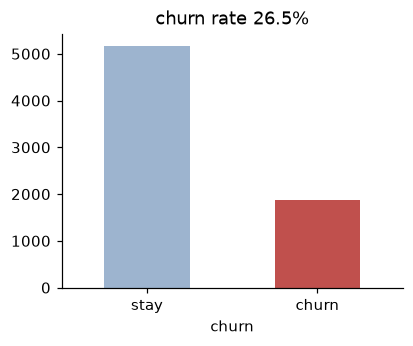

In [4]:
counts = df[config.TARGET].value_counts().rename({0: "stay", 1: "churn"})
fig, ax = plt.subplots(figsize=(4, 3))
counts.plot.bar(ax=ax, color=["#9db4cf", "#c0504d"], rot=0)
ax.set_title(f"churn rate {df[config.TARGET].mean():.1%}")
counts

## 3. Numeric variables

In [5]:
numeric = config.NUMERIC_FEATURES
df.groupby(config.TARGET)[numeric].describe().T.unstack(level=1).round(1)

churn                 0                                                       \
                  count    mean     std   min    25%     50%     75%     max   
tenure           5174.0    37.6    24.1   0.0   15.0    38.0    61.0    72.0   
monthly_charges  5174.0    61.3    31.1  18.2   25.1    64.4    88.4   118.8   
total_charges    5163.0  2555.3  2329.5  18.8  577.8  1683.6  4264.1  8672.4   

churn                 1                                                      
                  count    mean     std   min    25%    50%     75%     max  
tenure           1869.0    18.0    19.5   1.0    2.0   10.0    29.0    72.0  
monthly_charges  1869.0    74.4    24.7  18.8   56.2   79.6    94.2   118.4  
total_charges    1869.0  1531.8  1890.8  18.8  134.5  703.6  2331.3  8684.8

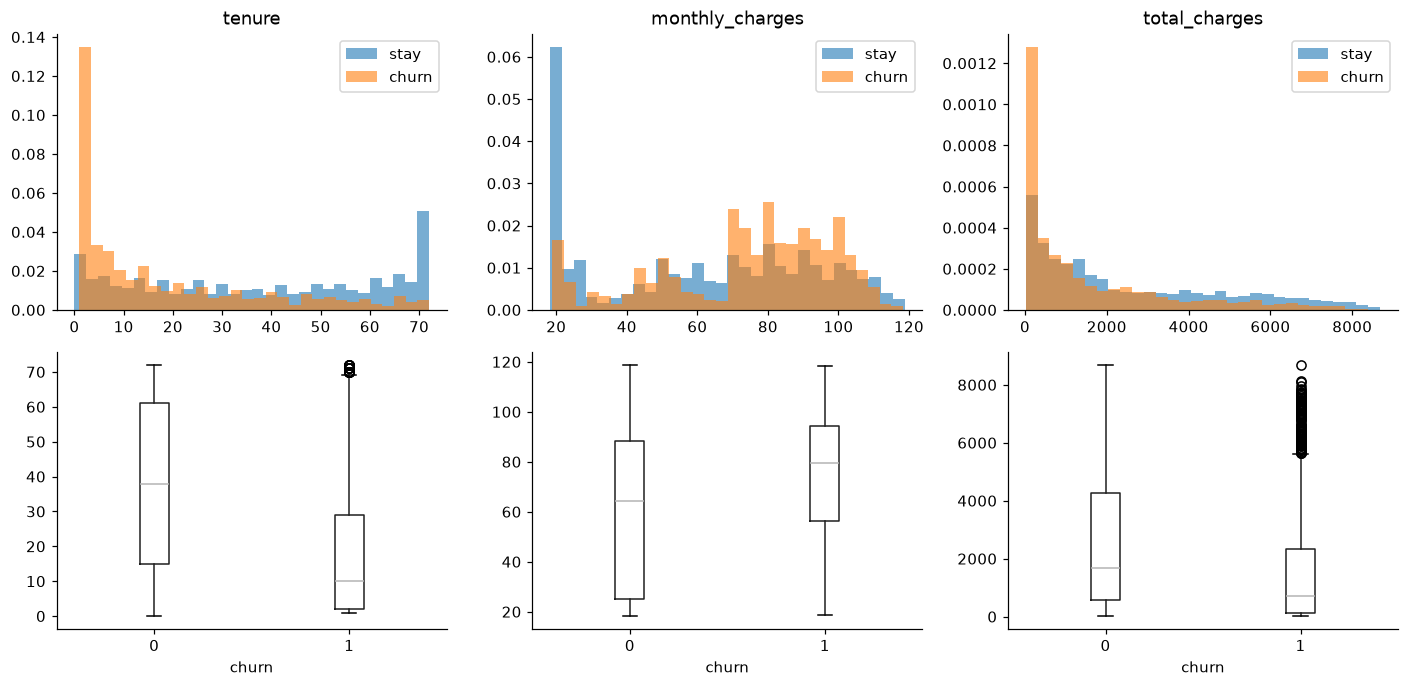

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for i, col in enumerate(numeric):
    for label, part in df.groupby(config.TARGET):
        axes[0, i].hist(part[col].dropna(), bins=30, alpha=0.6, density=True, label="churn" if label else "stay")
    axes[0, i].set_title(col)
    axes[0, i].legend()
    df.boxplot(column=col, by=config.TARGET, ax=axes[1, i], grid=False)
    axes[1, i].set_title("")
    axes[1, i].set_xlabel("churn")
fig.suptitle("")
fig.tight_layout()

Churners are newer and pay more. Median tenure is 10 months against 38, and median monthly charge is $79.6 against $64.4.
A quarter of all churners leave in their first two months.
`total_charges` looks protective, but only because it accumulates with tenure (section 7 shows how redundant it is).

## 4. Categorical variables

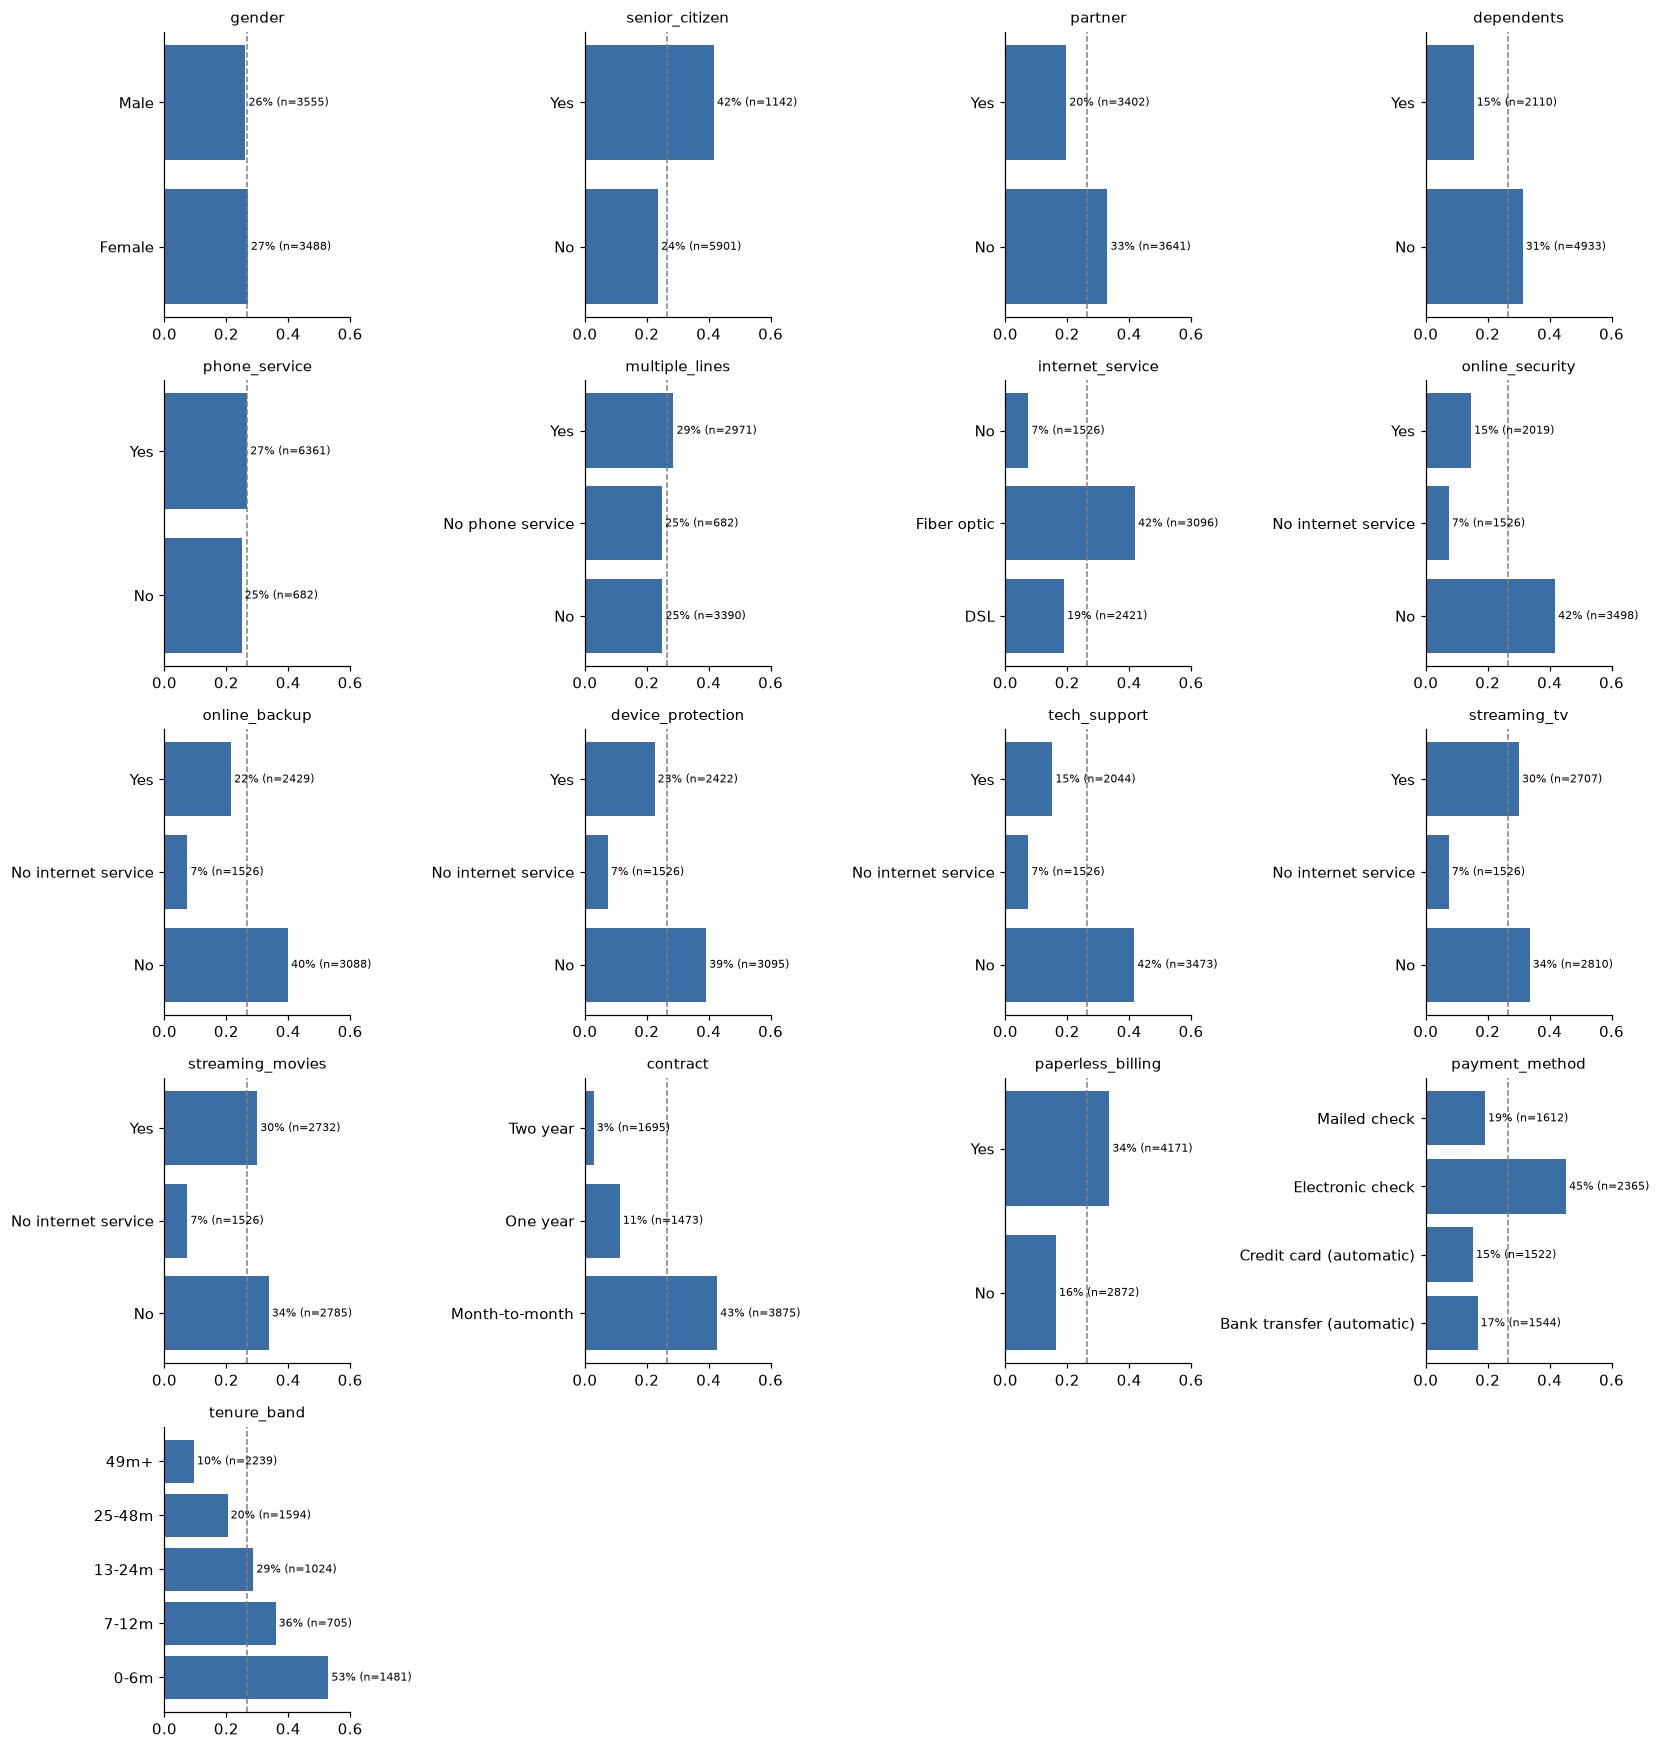

In [7]:
categorical = config.CATEGORICAL_FEATURES + ["tenure_band"]
fig, axes = plt.subplots(5, 4, figsize=(15, 16))
base_rate = df[config.TARGET].mean()
for ax, col in zip(axes.flat, categorical):
    rates = df.groupby(col)[config.TARGET].agg(["mean", "size"])
    if col == "tenure_band":
        rates = rates.reindex(config.TENURE_LABELS)
    ax.barh(rates.index.astype(str), rates["mean"], color="#3b6ea5")
    ax.axvline(base_rate, color="grey", ls="--", lw=1)
    ax.set_title(col, fontsize=10)
    ax.set_xlim(0, 0.6)
    for y, (rate, n) in enumerate(zip(rates["mean"], rates["size"])):
        ax.text(rate + 0.01, y, f"{rate:.0%} (n={n})", va="center", fontsize=7)
for ax in axes.flat[len(categorical):]:
    ax.axis("off")
fig.tight_layout()

## 5. Predictive power: Weight of Evidence and Information Value

WoE and IV are the standard univariate screening tools in credit and propensity modeling.
For each bin, `WoE = ln(% of non-churners / % of churners)`, and IV sums `(% non-churners - % churners) x WoE` over the bins.
Numeric variables are cut into 10 quantile bins.

Rule of thumb: IV < 0.02 useless, 0.02-0.1 weak, 0.1-0.3 medium, 0.3-0.5 strong. Above 0.5 is very strong, and in credit
scoring that's the point where you go check for leakage.

In [8]:
def woe_table(data, col, bins=10):
    x = pd.qcut(data[col], bins, duplicates="drop") if col in numeric else data[col]
    counts = pd.crosstab(x, data[config.TARGET])
    share_good = (counts[0] + 0.5) / counts[0].sum()
    share_bad = (counts[1] + 0.5) / counts[1].sum()
    table = pd.DataFrame({
        "n": counts.sum(axis=1),
        "churn_rate": counts[1] / counts.sum(axis=1),
        "woe": np.log(share_good / share_bad),
    })
    table["iv"] = (share_good - share_bad) * table["woe"]
    return table


def strength(iv):
    for limit, label in [(0.02, "useless"), (0.1, "weak"), (0.3, "medium"), (0.5, "strong")]:
        if iv < limit:
            return label
    return "very strong"


iv = pd.Series({col: woe_table(df, col)["iv"].sum() for col in config.FEATURES}).sort_values(ascending=False)
iv_table = iv.to_frame("iv").assign(strength=iv.map(strength))
iv_table

,iv,strength
contract,1.235e+00,very strong
tenure,8.199e-01,very strong
online_security,7.164e-01,very strong
tech_support,6.983e-01,very strong
internet_service,6.168e-01,very strong
online_backup,5.276e-01,very strong
device_protection,4.987e-01,strong
payment_method,4.565e-01,strong
streaming_movies,3.804e-01,strong
streaming_tv,3.795e-01,strong


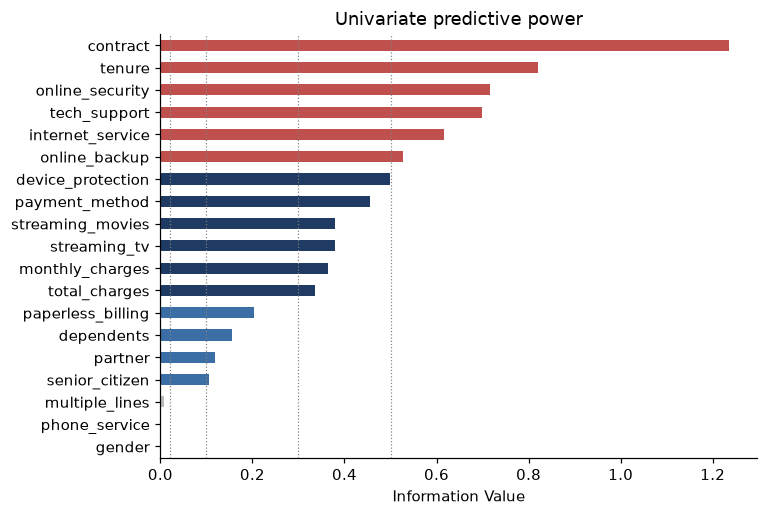

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
iv.iloc[::-1].plot.barh(ax=ax, color=[{"useless": "#bbb", "weak": "#9db4cf", "medium": "#3b6ea5", "strong": "#1f3b63", "very strong": "#c0504d"}[strength(v)] for v in iv.iloc[::-1]])
for x in (0.02, 0.1, 0.3, 0.5):
    ax.axvline(x, color="grey", ls=":", lw=0.8)
ax.set_xlabel("Information Value")
ax.set_title("Univariate predictive power");

In [10]:
woe_table(df, "tenure")

,n,churn_rate,woe,iv
tenure,,,,
"(-0.001, 2.0]",862,0.584,-1.355,0.271
"(2.0, 6.0]",619,0.454,-0.834,0.071
"(6.0, 12.0]",705,0.359,-0.439,0.021
"(12.0, 20.0]",692,0.309,-0.216,0.005
"(20.0, 29.0]",691,0.229,0.195,0.004
"(29.0, 40.0]",717,0.219,0.251,0.006
"(40.0, 50.0]",652,0.176,0.519,0.022
"(50.0, 60.0]",698,0.136,0.825,0.054
"(60.0, 69.0]",756,0.093,1.258,0.119


- **Contract (IV 1.24), tenure (0.82) and the "protection" services** (online security 0.72, tech support 0.70) dominate.
  In credit scoring an IV this high would make me look for leakage. Here it doesn't apply: contract type and tenure are known at the snapshot date and
  don't encode the outcome. Churn in telecom really is mostly a contract story.
- **Gender (0.0004), phone service (0.0007) and multiple lines (0.008) carry essentially no signal.**
- The tenure WoE table is monotonic, from -1.36 in the first two months to +2.27 after 69 months, with no reversals. That's the shape you want before trusting a variable.

## 6. Univariate Gini on train vs test

The same screening as a stability check: each variable alone is used as a score (category churn rate learned on train, raw value for numerics),
and its Gini is measured on train and on test. A variable whose Gini collapses on test is fitting noise.

In [11]:
from sklearn.metrics import roc_auc_score

train, test = load_split("train"), load_split("test")


def univariate_gini(col):
    if col in numeric:
        fill = train[col].median()
        g_train = 2 * roc_auc_score(train[config.TARGET], train[col].fillna(fill)) - 1
        g_test = 2 * roc_auc_score(test[config.TARGET], test[col].fillna(fill)) - 1
        return abs(g_train), abs(g_test)
    rates = train.groupby(col)[config.TARGET].mean()
    g_train = 2 * roc_auc_score(train[config.TARGET], train[col].map(rates)) - 1
    g_test = 2 * roc_auc_score(test[config.TARGET], test[col].map(rates).fillna(rates.mean())) - 1
    return g_train, g_test


gini = pd.DataFrame({col: univariate_gini(col) for col in config.FEATURES}, index=["gini_train", "gini_test"]).T
gini["fill_rate"] = df[config.FEATURES].notna().mean()
gini["drop"] = gini["gini_train"] - gini["gini_test"]
gini.sort_values("gini_train", ascending=False)

,gini_train,gini_test,fill_rate,drop
contract,0.484,0.533,1.000,-0.049
tenure,0.457,0.535,1.000,-0.078
online_security,0.430,0.440,1.000,-0.010
tech_support,0.430,0.461,1.000,-0.031
internet_service,0.408,0.405,1.000,0.002
online_backup,0.355,0.402,1.000,-0.047
device_protection,0.341,0.399,1.000,-0.058
payment_method,0.339,0.426,1.000,-0.087
total_charges,0.274,0.336,0.998,-0.062
monthly_charges,0.266,0.251,1.000,0.015


No variable degrades from train to test. Every drop is within a few points, and most are negative: test happens to be slightly easier than train for this draw.

The methodology's screening rule (keep a variable if Gini > 5% with fill rate > 80%, or stricter combinations for sparser variables) would **drop `gender` (Gini 0.014)
and `phone_service` (0.019)**, and leave `multiple_lines` (0.051) borderline. I keep them in the pipeline for now because both candidate model types handle
uninformative columns and the cost is small. Removing `gender` is the first simplification I'd make, and it would also remove a protected attribute from the model.

## 7. Redundancy

cramers_v
phone_service     multiple_lines        1.000
streaming_tv      streaming_movies      0.771
device_protection streaming_movies      0.736
                  streaming_tv          0.734
online_security   tech_support          0.733
device_protection tech_support          0.726
internet_service  online_security       0.724
                  tech_support          0.723

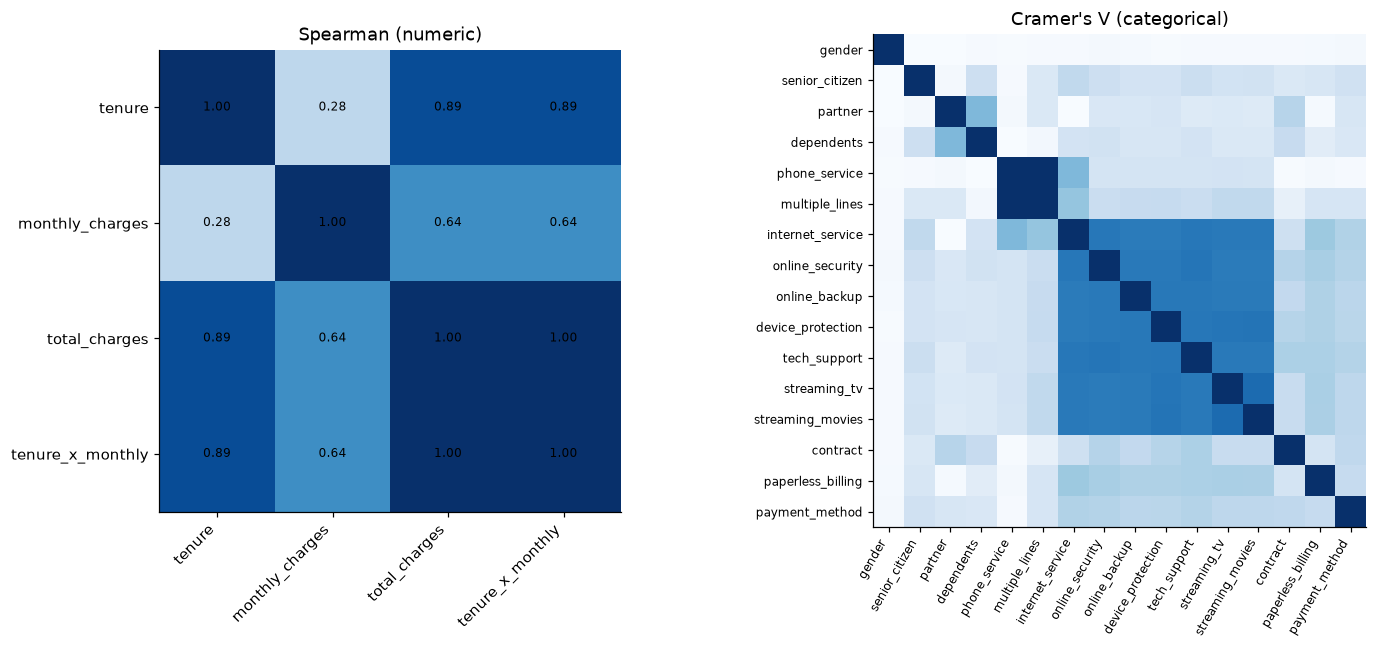

In [12]:
from scipy.stats import chi2_contingency


def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


cats = config.CATEGORICAL_FEATURES
v = pd.DataFrame([[cramers_v(df[a], df[b]) for b in cats] for a in cats], index=cats, columns=cats)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 2.2]})
num = df[numeric].assign(tenure_x_monthly=df["tenure"] * df["monthly_charges"]).corr(method="spearman")
im = axes[0].imshow(num, cmap="Blues", vmin=0, vmax=1)
axes[0].set_xticks(range(len(num)), num.columns, rotation=45, ha="right")
axes[0].set_yticks(range(len(num)), num.columns)
for i in range(len(num)):
    for j in range(len(num)):
        axes[0].text(j, i, f"{num.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
axes[0].set_title("Spearman (numeric)")
axes[1].imshow(v, cmap="Blues", vmin=0, vmax=1)
axes[1].set_xticks(range(len(cats)), cats, rotation=60, ha="right", fontsize=8)
axes[1].set_yticks(range(len(cats)), cats, fontsize=8)
axes[1].set_title("Cramer's V (categorical)")
fig.tight_layout()

pairs = v.where(np.triu(np.ones(v.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
pairs.head(8).to_frame("cramers_v")

- `phone_service` and `multiple_lines` have Cramér's V = 1.0. That's structural: `multiple_lines = "No phone service"` exactly when `phone_service = "No"`.
- The add-on services correlate with each other at 0.72-0.77 for the same reason: they share the `"No internet service"` level. Part of their signal is simply
  "has internet or not", which `internet_service` already carries.
- On the numeric side, `total_charges` is almost identical to `tenure x monthly_charges` (Spearman ~1). On its own it adds very little, which motivates the
  `avg_monthly_spend` feature in notebook 02 and is why the stress test can't move it independently.

## 8. Interactions

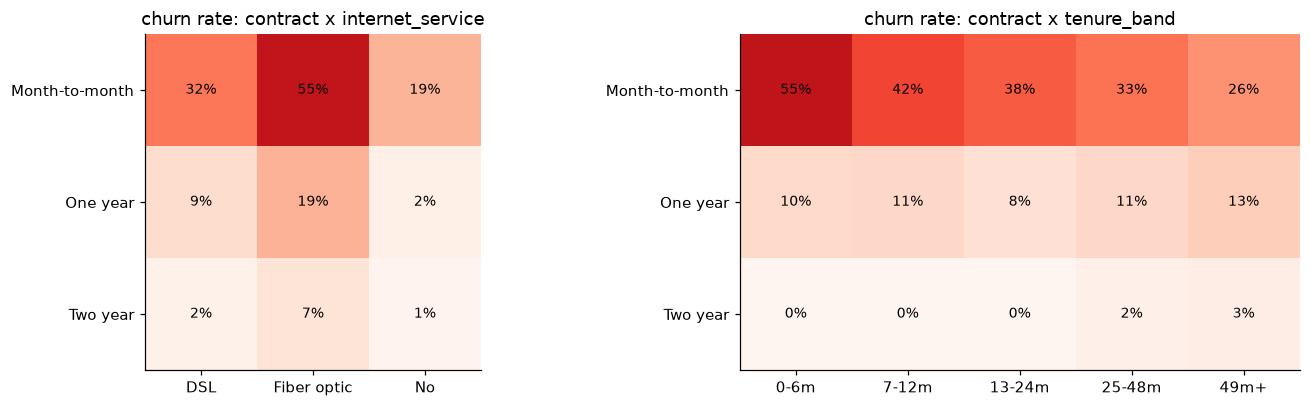

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (rows, cols) in zip(axes, [("contract", "internet_service"), ("contract", "tenure_band")]):
    pivot = df.pivot_table(index=rows, columns=cols, values=config.TARGET, aggfunc="mean")
    if cols == "tenure_band":
        pivot = pivot[config.TENURE_LABELS]
    ax.imshow(pivot, cmap="Reds", vmin=0, vmax=0.7)
    ax.set_xticks(range(pivot.shape[1]), pivot.columns)
    ax.set_yticks(range(pivot.shape[0]), pivot.index)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            ax.text(j, i, f"{pivot.iloc[i, j]:.0%}", ha="center", va="center", fontsize=9)
    ax.set_title(f"churn rate: {rows} x {cols}")
fig.tight_layout()

Contract and internet service compound. Month-to-month customers on fiber churn at 55%, against 32% on DSL, while fiber on a two-year contract churns at only 7%.
Within month-to-month, churn falls steadily with tenure, from 55% in the first six months to 26% after four years, and it never reaches the level of two-year contracts
(0-3%) even for brand-new ones. Inside one-year contracts tenure barely matters (8-13%).
The effect of tenure depends on the contract, which a single linear term per variable can't express. That's part of why tree models are worth comparing in notebook 03.

## 9. Representativeness of the frozen split

The split is stratified on the target, so churn rates match by construction. The real question is whether the features are distributed the same way.
I use the same PSI the production monitor uses, comparing each sample against train.

In [14]:
from churn.monitoring.drift import feature_drift

samples = {name: load_split(name) for name in ["train", "test", "holdout", "production_pool"]}
summary = pd.DataFrame({
    name: {
        "rows": len(part),
        "churn_rate": part[config.TARGET].mean(),
        "max_psi_vs_train": feature_drift(samples["train"], part)[0]["psi"],
        "most_shifted": feature_drift(samples["train"], part)[0]["feature"],
    }
    for name, part in samples.items()
}).T
summary

,rows,churn_rate,max_psi_vs_train,most_shifted
train,2816,0.265,0.0,tenure
test,705,0.265,0.019,tenure
holdout,1409,0.265,0.017,total_charges
production_pool,2113,0.265,0.011,monthly_charges


All four samples have the same churn rate (26.5%), and no feature shifts by more than PSI 0.019 against train, an order of magnitude below the 0.10 warning level.
The split is representative, so later differences between test and holdout come from model selection, not from different populations.

## What I take into modeling

| Finding | Decision |
|---|---|
| 26.5% positives, costs are asymmetric | Measure Gini/KS and recall on the business decision, never accuracy |
| Contract and tenure dominate, with strong interactions | Logistic regression as an honest baseline; tree models must earn their complexity |
| Add-on services are partly redundant via "no internet" | Keep them; one-hot encoding handles the shared level |
| `total_charges` ≈ `tenure x monthly_charges` | Add `avg_monthly_spend`; flag `total_charges` in the stress test |
| `gender`, `phone_service` carry no signal | First candidates to drop |
| New customers churn at 53% | Monitor the 0-6 month segment separately |
| Split is representative (max PSI 0.019) | Differences between test and holdout are about selection, not population |